# Cổ phiếu Mỹ: LSTM so với RNN (cùng dữ liệu, cùng siêu tham số)

**Nhóm 5:** Nguyễn Phú Đại · Trần Vũ Tiến Minh · Trần Đình Hiếu · Phạm Thanh An

Notebook này đặt **LSTM** cạnh **RNN** trên đúng bài toán của `A6/source/stock.ipynb`:

- **Dữ liệu:** giá ngày (Open, High, Low, Close, Volume) của Apple (`aapl`), Microsoft (`msft`) và HP (`hpq`), dự đoán từ năm 1995 đến 2025-12-03.
- **Bài toán:** dự đoán **biên độ giao dịch ngày mai** `ln(High / Low)` (tính bằng %) từ 60 ngày giao dịch trước đó (hồi quy *many-to-one*). Biên độ có tự tương quan mạnh và giảm chậm (vẫn ≈ 0.34 ở độ trễ 60 ngày), nên đây là bài toán có phụ thuộc dài hạn.

**Thiết kế để so sánh công bằng.** Mọi thứ giống notebook RNN, chỉ khác lớp hồi quy:

| | RNN (A6) | LSTM (notebook này) |
|---|---|---|
| Tiền xử lý, 9 đặc trưng/ngày, cửa sổ 60 ngày, chia train / val / test theo ngày dự đoán | giống hệt (code chép nguyên từ A6) | giống hệt |
| Kiến trúc | `nn.RNN(9→64)` → `nn.RNN(64→32)` → `Linear(32→1)` | `nn.LSTM(9→64)` → `nn.LSTM(64→32)` → `Linear(32→1)` |
| Huấn luyện | Adam lr 1e-3, batch 128, 30 epoch, clip 1.0, MSE, giữ epoch có val loss thấp nhất | giống hệt |
| Khởi tạo | Glorot (W_x), trực giao (W_h), bias 0 | giống hệt; riêng bias cổng quên = 1 (mặc định của Keras) |

Mỗi mô hình chạy **5 seed** (42, 0, 1, 2, 3). RNN với seed 42 dùng đúng trọng số khởi tạo và thứ tự batch của A6, nên phải ra lại đúng kết quả A6 (MAE 0.7246 điểm %). Đây là bước kiểm tra tái lập.

Mục 9 thêm một thí nghiệm: **thay đổi độ dài cửa sổ** (20, 60, 120 ngày) trên cùng một tập mẫu, để xem mô hình nào tận dụng được lịch sử dài hơn.

**Mục lục**
1. Thiết lập
2. Tiền xử lý (chép từ A6)
3. Mô hình RNN và LSTM
4. Huấn luyện (2 mô hình × 5 seed, cửa sổ 60 ngày)
5. So sánh: chỉ số trên tập test
6. Đường học
7. Mô hình nhìn xa bao nhiêu ngày? (độ nhạy theo thời gian, cắt cửa sổ)
8. Sai số theo cổ phiếu và theo mức biến động
9. Thí nghiệm độ dài cửa sổ: 20 / 60 / 120 ngày
10. Chi phí, lưu kết quả và kết luận

## 1. Thiết lập

Hằng số giống `A6/source/stock.ipynb`. Dữ liệu đọc từ thư mục `A6/data/`; nếu không có thì `kagglehub` tải về. Hình lưu vào `experiment/figures/`, số liệu tổng hợp lưu vào `experiment/results/lstm_stock.json`.

In [1]:
import copy
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import torch
import torch.nn as nn
from torch import Tensor

torch.set_flush_denormal(True)
torch.set_num_threads(4)

SEED       = 42
SEEDS      = [42, 0, 1, 2, 3]
WINDOW     = 60                 # trading days of history in one input sequence
H1, H2     = 64, 32             # hidden units of recurrent layer 1 and layer 2
BATCH_SIZE = 128
EPOCHS     = 30
LR         = 1e-3
BETA1      = 0.9
BETA2      = 0.999
EPS        = 1e-7
CLIP       = 1.0                # maximum global gradient norm

SWEEP_WINDOWS = [20, 60, 120]   # section 9
SWEEP_SEEDS   = [42, 0, 1]

FIRST_TARGET = pd.Timestamp('1995-01-01')   # first predicted day
VAL_START    = pd.Timestamp('2017-01-01')   # validation targets: 2017-01-01 .. 2019-12-31
TEST_START   = pd.Timestamp('2020-01-01')   # test targets:       2020-01-01 .. 2025-12-03

TICKERS  = ['aapl', 'msft', 'hpq']
A6_DIR   = Path('../../Phát triển hệ thống thông minh/A6')
DATA_DIR = A6_DIR / 'data' / 'us-stock-price'
if not all((DATA_DIR / f'{ticker}_us_d.csv').exists() for ticker in TICKERS):
    import kagglehub, shutil
    DATA_DIR = Path('data/us-stock-price')
    shutil.copytree(kagglehub.dataset_download('habiburrohman/us-stock-price'), DATA_DIR, dirs_exist_ok=True)
FIG_DIR    = Path('figures')
RESULT_DIR = Path('results')
FIG_DIR.mkdir(exist_ok=True)
RESULT_DIR.mkdir(exist_ok=True)

# Results of the PyTorch RNN in A6/source/stock.ipynb (section 12), used to check that the RNN here is the same run
A6_RNN = {'MAE': 0.7246, 'R2 log': 0.3445, 'best_epoch': 4}

CELLS         = ['RNN', 'LSTM']
COLORS        = {'RNN': '#eb6834', 'LSTM': '#2a78d6', 'naive': '#9a9a9a', 'mean 5 days': '#c4a35a', 'mean 20 days': '#d4b5e8',
                 'HAR': '#7a5cc4', 'actual': '#222222'}
TICKER_COLORS = {'aapl': '#2a78d6', 'msft': '#1baf7a', 'hpq': '#eb6834'}

np.random.seed(SEED)
torch.manual_seed(SEED)

plt.rcParams.update({
    'figure.dpi': 110,
    'savefig.dpi': 150,
    'savefig.bbox': 'tight',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'axes.axisbelow': True,
    'grid.alpha': 0.3,
    'lines.linewidth': 2,
})

print(f'numpy {np.__version__} | pandas {pd.__version__} | torch {torch.__version__} | torch threads: {torch.get_num_threads()}')
print('data dir:', DATA_DIR.resolve(), sorted(p.name for p in DATA_DIR.iterdir()))

numpy 2.4.6 | pandas 3.0.3 | torch 2.14.0+cpu | torch threads: 4
data dir: /home/storie/Code/Phát triển hệ thống thông minh/A6/data/us-stock-price ['aapl_trend.csv', 'aapl_us_d.csv', 'hpq_trend.csv', 'hpq_us_d.csv', 'msft_trend.csv', 'msft_us_d.csv']


## 2. Tiền xử lý (chép nguyên từ A6)

Các ô dưới đây là code của `A6/source/stock.ipynb` (mục 2.1, 4.1, 4.2, 5.1, 5.2), bỏ các biểu đồ phân tích dữ liệu. Giải thích chi tiết nằm trong notebook A6.

### 2.1 Đọc giá ngày của 3 cổ phiếu

In [2]:
prices = {ticker: pd.read_csv(DATA_DIR / f'{ticker}_us_d.csv', parse_dates=['Date'], index_col='Date') for ticker in TICKERS}

display(pd.DataFrame({
    ticker: {
        'rows':               len(p),
        'first day':          p.index.min().date(),
        'last day':           p.index.max().date(),
        'duplicated dates':   p.index.duplicated().sum(),
        'missing values':     p.isna().sum().sum(),
        'High == Low':        (p.High == p.Low).sum(),
        'High < Open/Close':  (p.High < p[['Open', 'Close']].max(axis=1)).sum(),
        'Low > Open/Close':   (p.Low > p[['Open', 'Close']].min(axis=1)).sum(),
        'Volume <= 0':        (p.Volume <= 0).sum(),
        'longest gap (days)': p.index.to_series().diff().dt.days.max(),
        'first Close':        p.Close.iloc[0],
        'last Close':         p.Close.iloc[-1],
    }
    for ticker, p in prices.items()
}).T)

prices['aapl'].head()

,rows,first day,last day,duplicated dates,missing values,High == Low,High < Open/Close,Low > Open/Close,Volume <= 0,longest gap (days),first Close,last Close
aapl,10391,1984-09-07,2025-12-03,0,0,27,0,0,0,7.0,0.099605,284.17
msft,10008,1986-03-13,2025-12-03,0,0,248,0,0,1,7.0,0.069028,477.36
hpq,14100,1970-01-02,2025-12-03,0,0,88,0,0,1,7.0,0.261322,25.19


,Open,High,Low,Close,Volume
Date,,,,,
1984-09-07,0.099605,0.100827,0.098402,0.099605,98811715
1984-09-10,0.099605,0.099910,0.097210,0.099014,76694011
1984-09-11,0.099910,0.102620,0.099910,0.100827,180849030
1984-09-12,0.100827,0.101417,0.097791,0.097791,157987052
1984-09-13,0.103232,0.103526,0.103232,0.103232,246058991


### 2.2 Sáu đặc trưng mỗi ngày

`range` = ln(ln(High/Low)) (chính là chuỗi mục tiêu, thang log), `ret`, `gap`, `body`, `close_pos`, `volume` (so với trung bình 50 ngày). Ngày lỗi (High == Low, Volume ≤ 0) được đánh dấu `bad`.

In [3]:
frames = {}
for ticker, p in prices.items():
    log_volume = np.log(p.Volume.where(p.Volume > 0))
    frames[ticker] = pd.DataFrame({
        'range':     np.log(np.log(p.High / p.Low).where(p.High > p.Low)),
        'ret':       np.log(p.Close).diff(),
        'gap':       np.log(p.Open / p.Close.shift()),
        'body':      np.log(p.Close / p.Open),
        'close_pos': ((p.Close - p.Low) / (p.High - p.Low)).where(p.High > p.Low),
        'volume':    log_volume - log_volume.rolling(50, min_periods=40).mean(),
    }).iloc[50:]
    frames[ticker]['bad'] = frames[ticker].isna().any(axis=1)

print({t: f'{len(f):,} days, {f.bad.sum()} bad' for t, f in frames.items()})
frames['aapl'].describe().T.round(4)

{'aapl': '10,341 days, 27 bad', 'msft': '9,958 days, 213 bad', 'hpq': '14,050 days, 81 bad'}


,count,mean,std,min,25%,50%,75%,max
range,10314.0,-3.6543,0.5992,-5.9121,-4.0657,-3.6476,-3.2441,-1.1836
ret,10341.0,0.0008,0.0273,-0.7308,-0.0120,0.0003,0.0139,0.2871
gap,10341.0,0.0009,0.0161,-0.6403,-0.0041,0.0000,0.0059,0.2448
body,10341.0,-0.0001,0.0225,-0.2794,-0.0113,0.0000,0.0110,0.1771
close_pos,10314.0,0.5051,0.3139,0.0000,0.2254,0.5074,0.7905,1.0000
volume,10341.0,-0.0028,0.4559,-4.1701,-0.2902,-0.0463,0.2441,3.2573


### 2.3 Chuẩn hóa (thống kê của các ngày trước `VAL_START`), cắt ±5, thêm 3 cờ cổ phiếu → 9 đầu vào

In [4]:
FEATURES = ['range', 'ret', 'gap', 'body', 'close_pos', 'volume']
fit = pd.concat([f.loc[(f.index < VAL_START) & ~f.bad, FEATURES] for f in frames.values()])
stats = fit.agg(['mean', 'std'])

for i, (ticker, f) in enumerate(frames.items()):
    scaled = ((f[FEATURES] - stats.loc['mean']) / stats.loc['std']).clip(-5, 5).fillna(0)
    for other in TICKERS:
        scaled[f'is_{other}'] = float(other == ticker)
    frames[ticker] = pd.concat([scaled, f[['bad']], f.range.rename('log_range')], axis=1)

INPUTS = FEATURES + [f'is_{t}' for t in TICKERS]
F = len(INPUTS)
clipped = (((fit - stats.loc['mean']) / stats.loc['std']).abs() > 5).mean()

print(f'{F} inputs: {INPUTS}')
print(f'scaler of range (log scale): mean {stats.loc["mean", "range"]:.4f}, std {stats.loc["std", "range"]:.4f} '
      f'-> typical range {100 * np.exp(stats.loc["mean", "range"]):.2f} %')
print('share of training values clipped at ±5:', clipped.round(5).to_dict())
stats.round(5)

9 inputs: ['range', 'ret', 'gap', 'body', 'close_pos', 'volume', 'is_aapl', 'is_msft', 'is_hpq']
scaler of range (log scale): mean -3.6958, std 0.5655 -> typical range 2.48 %
share of training values clipped at ±5: {'range': 0.0, 'ret': 0.00227, 'gap': 0.0052, 'body': 0.00227, 'close_pos': 0.0, 'volume': 0.00066}


,range,ret,gap,body,close_pos,volume
mean,-3.69583,0.00057,0.00033,0.00024,0.49962,0.00349
std,0.56553,0.02518,0.01360,0.02129,0.32905,0.45611


### 2.4 Cửa sổ trượt 60 ngày và các dự báo tham chiếu

Cửa sổ bị bỏ nếu chạm một ngày lỗi hoặc ngày mục tiêu trước `FIRST_TARGET`. `meta` giữ các dự báo tham chiếu: **naive** (biên độ hôm nay), **mean 5 / 20 days**, và đầu vào của **HAR** (mô hình tuyến tính chuẩn cho biến động: hôm nay + trung bình 5 ngày + trung bình 22 ngày).

In [5]:
X, y, meta = [], [], []
for ticker, f in frames.items():
    log_range = f.log_range                                                             # unscaled ln(range), NaN on bad days
    windows = np.lib.stride_tricks.sliding_window_view(f[INPUTS].to_numpy('float32')[:-1], WINDOW, axis=0).transpose(0, 2, 1)  # (n, 60, 9)
    touches_bad = np.lib.stride_tricks.sliding_window_view(f.bad.to_numpy(), WINDOW + 1).any(axis=1)
    keep = ~touches_bad & (f.index[WINDOW:] >= FIRST_TARGET)

    X.append(windows[keep])
    y.append(((log_range - stats.loc['mean', 'range']) / stats.loc['std', 'range']).to_numpy('float32')[WINDOW:, None][keep])   # (n, 1)
    meta.append(pd.DataFrame({
        'ticker':      ticker,
        'target_day':  f.index[WINDOW:],
        'true':        log_range.to_numpy()[WINDOW:],
        'naive':       log_range.to_numpy()[WINDOW - 1:-1],
        'mean5':       log_range.rolling(5).mean().to_numpy()[WINDOW - 1:-1],
        'mean20':      log_range.rolling(20).mean().to_numpy()[WINDOW - 1:-1],
        'mean22':      log_range.rolling(22).mean().to_numpy()[WINDOW - 1:-1],
    })[keep])
    print(f'{ticker}: {len(keep):,} windows, {touches_bad.sum()} touch a bad day, {keep.sum():,} kept')

X, y, meta = np.concatenate(X), np.concatenate(y), pd.concat(meta, ignore_index=True)
meta['split'] = np.select([meta.target_day < VAL_START, meta.target_day < TEST_START], ['train', 'val'], 'test')
print(f'X {X.shape} (windows, days, inputs) | y {y.shape} | NaN in X: {np.isnan(X).sum()} | NaN in reference inputs: {meta.isna().sum().sum()}')

aapl: 10,281 windows, 241 touch a bad day, 7,782 kept
msft: 9,898 windows, 999 touch a bad day, 7,720 kept


hpq: 13,990 windows, 1569 touch a bad day, 7,721 kept
X (23223, 60, 9) (windows, days, inputs) | y (23223, 1) | NaN in X: 0 | NaN in reference inputs: 0


### 2.5 Chia train / validation / test theo ngày dự đoán; khớp HAR trên tập train

| Phần | Ngày mục tiêu | Dùng để |
|---|---|---|
| train | 1995-01-03 … 2016-12-30 | cập nhật trọng số, khớp scaler và HAR |
| validation | 2017-01-03 … 2019-12-31 | chọn epoch tốt nhất |
| test | 2020-01-02 … 2025-12-03 | chỉ để so sánh cuối cùng |

In [6]:
X_train, y_train = X[(meta.split == 'train').to_numpy()], y[(meta.split == 'train').to_numpy()]
X_val,   y_val   = X[(meta.split == 'val').to_numpy()],   y[(meta.split == 'val').to_numpy()]
X_test,  y_test  = X[(meta.split == 'test').to_numpy()],  y[(meta.split == 'test').to_numpy()]

har = LinearRegression().fit(meta.loc[meta.split == 'train', ['naive', 'mean5', 'mean22']], meta.true[meta.split == 'train'])
meta['har'] = har.predict(meta[['naive', 'mean5', 'mean22']])
print(f'HAR: ln(range) = {har.intercept_:.3f} + {har.coef_[0]:.3f} * last day + {har.coef_[1]:.3f} * mean 5 + {har.coef_[2]:.3f} * mean 22')

val_meta, test_meta = meta[meta.split == 'val'].reset_index(drop=True), meta[meta.split == 'test'].reset_index(drop=True)
X_check, y_check = X_train[:64], y_train[:64]
results = {}

display(meta.groupby(['split', 'ticker'], sort=False).agg(windows=('true', 'size'), first_target=('target_day', 'min'),
                                                           last_target=('target_day', 'max'), mean_range_pct=('true', lambda v: round(100 * np.exp(v).mean(), 3))))
print(f'X_train {X_train.shape} | X_val {X_val.shape} | X_test {X_test.shape}')

HAR: ln(range) = -0.250 + 0.197 * last day + 0.289 * mean 5 + 0.446 * mean 22


,,windows,first_target,last_target,mean_range_pct
split,ticker,,,,
train,aapl,5539,1995-01-03,2016-12-30,3.334
val,aapl,754,2017-01-03,2019-12-31,1.680
test,aapl,1489,2020-01-02,2025-12-03,2.257
train,msft,5477,1995-01-03,2016-12-30,2.387
val,msft,754,2017-01-03,2019-12-31,1.634
test,msft,1489,2020-01-02,2025-12-03,2.083
train,hpq,5478,1995-01-03,2016-12-30,2.937
val,hpq,754,2017-01-03,2019-12-31,1.987
test,hpq,1489,2020-01-02,2025-12-03,2.662


X_train (16494, 60, 9) | X_val (2262, 60, 9) | X_test (4467, 60, 9)


## 3. Mô hình RNN và LSTM

Một lớp `SeqNet` dùng cho cả hai; tham số `cell` chọn `nn.RNN` hay `nn.LSTM`. Cùng số lớp, cùng số đơn vị ẩn (64 và 32), cùng đầu ra `Linear(32 → 1)` trên trạng thái ẩn của ngày cuối.

**Khác biệt duy nhất là ô hồi quy:**

- RNN: $h_t = \tanh(W_x x_t + W_h h_{t-1} + b)$. Gradient đi ngược qua $k$ ngày bị nhân $k$ lần với $\operatorname{diag}(1-h^2)\,W_h$. A6 đo được: gradient ở ngày 1 chỉ còn $2.6 \cdot 10^{-8}$ lần so với ngày 60, và RNN gần như chỉ dùng 20 ngày cuối.
- LSTM: thêm **cell state** $c_t = f_t \odot c_{t-1} + i_t \odot \tilde c_t$ và 3 cổng (quên $f$, vào $i$, ra $o$), $h_t = o_t \odot \tanh(c_t)$. Gradient đi dọc $c_t$ chỉ bị nhân với $f_t$; khi $f_t \approx 1$, thông tin của những ngày xa vẫn truyền tới được.

**Khởi tạo** (hàm `init_weights`, sinh từ `np.random.default_rng(seed)` theo đúng thứ tự của A6): $W_x$ Glorot uniform; $W_h$ trực giao (LSTM: một khối trực giao cho mỗi cổng); bias 0; riêng LSTM có bias cổng quên = 1. `bias_hh` của PyTorch được đặt 0 và đóng băng như A6. Với `cell='RNN'` và `seed=42`, `init_weights` sinh ra **đúng** trọng số `init` của A6.

In [7]:
class SeqNet(nn.Module):
    def __init__(self, cell: str, n_in: int, n_out: int = 1):
        super().__init__()
        layer = nn.LSTM if cell == 'LSTM' else nn.RNN
        self.cell = cell
        self.rnn1 = layer(n_in, H1, batch_first=True)       # (_, T, 9)  -> (_, T, 64)
        self.rnn2 = layer(H1, H2, batch_first=True)         # (_, T, 64) -> (_, T, 32)
        self.head = nn.Linear(H2, n_out)                    # (_, 32)    -> (_, 1)

        for rnn in (self.rnn1, self.rnn2):                  # one trainable bias per layer, as in A6
            nn.init.zeros_(rnn.bias_hh_l0)
            rnn.bias_hh_l0.requires_grad_(False)

    def forward(self, x: Tensor) -> Tensor:
        x, _ = self.rnn1(x)
        x, _ = self.rnn2(x)
        return self.head(x[:, -1])                          # last day -> prediction


def init_weights(model: SeqNet, seed: int) -> None:
    """Glorot W_x, orthogonal W_h, zero bias (LSTM: forget-gate bias 1). Same draw order as A6."""
    rng = np.random.default_rng(seed)
    gates = 4 if model.cell == 'LSTM' else 1
    with torch.no_grad():
        for rnn, n_in, h in ((model.rnn1, model.rnn1.input_size, H1), (model.rnn2, H1, H2)):
            Wx = rng.uniform(-1, 1, (n_in, gates * h)) * np.sqrt(6 / (n_in + gates * h))
            Wh = np.concatenate([np.linalg.qr(rng.normal(size=(h, h)))[0] for _ in range(gates)], axis=1)
            b = np.zeros(gates * h)
            if model.cell == 'LSTM':
                b[h:2 * h] = 1.0                            # PyTorch gate order: input, forget, cell, output
            rnn.weight_ih_l0.copy_(torch.tensor(Wx.T, dtype=torch.float32))
            rnn.weight_hh_l0.copy_(torch.tensor(Wh.T, dtype=torch.float32))
            rnn.bias_ih_l0.copy_(torch.tensor(b, dtype=torch.float32))
        n_out = model.head.out_features
        model.head.weight.copy_(torch.tensor((rng.uniform(-1, 1, (H2, n_out)) * np.sqrt(6 / (H2 + n_out))).T, dtype=torch.float32))
        nn.init.zeros_(model.head.bias)


rows = []
for cell in CELLS:
    model = SeqNet(cell, F)
    for name, p in model.named_parameters():
        rows.append({'model': cell, 'parameter': name, 'count': p.numel() if p.requires_grad else 0})
param_table = pd.DataFrame(rows)
display(param_table.pivot_table(index='parameter', columns='model', values='count', aggfunc='sum', sort=False))
print({cell: f'{param_table[param_table.model == cell]["count"].sum():,} trainable parameters' for cell in CELLS})

model,RNN,LSTM
parameter,,
rnn1.weight_ih_l0,576,2304
rnn1.weight_hh_l0,4096,16384
rnn1.bias_ih_l0,64,256
rnn1.bias_hh_l0,0,0
rnn2.weight_ih_l0,2048,8192
rnn2.weight_hh_l0,1024,4096
rnn2.bias_ih_l0,32,128
rnn2.bias_hh_l0,0,0
head.weight,32,32


{'RNN': '7,873 trainable parameters', 'LSTM': '31,393 trainable parameters'}


### 3.1 Bên trong `nn.RNN` và `nn.LSTM`: viết lại bằng NumPy

`nn.RNN` và `nn.LSTM` của PyTorch là "hộp đen". Ô dưới đây viết lại **toàn bộ lượt tính xuôi** của `SeqNet` chỉ bằng NumPy, để thấy hai mô hình được ghép từ những hàm nào. Sau đó chép trọng số từ mô hình PyTorch sang và kiểm tra hai bên cho ra cùng một dự báo.

**Các viên gạch:**

| Hàm | RNN | LSTM | Vai trò |
|---|---|---|---|
| `affine(x, W, b)` = $xW^\top + b$ | ✓ | ✓ | kết hợp đầu vào của ngày hiện tại và trạng thái ẩn của ngày trước bằng trọng số |
| `np.tanh` | ✓ trạng thái ẩn | ✓ nội dung mới $g$, đọc bộ nhớ | ép giá trị về khoảng (−1, 1) |
| `sigmoid` | | ✓ 3 cổng $i, f, o$ | "van" mở từ 0 đến 1 |
| nhân từng phần tử `*` | | ✓ | áp cổng lên bộ nhớ / nội dung mới / đầu ra |
| cộng `f * c + i * g` | | ✓ | cập nhật bộ nhớ: xóa bớt rồi cộng thêm |
| vòng `for` qua $T$ ngày | ✓ | ✓ | lặp **cùng một** hàm bước, **cùng** trọng số, qua 60 ngày |

**Ghép lại:**

```
một bước   rnn_step  : h_t = tanh(affine(x_t) + affine(h_{t-1}))
           lstm_step : z = affine(x_t) + affine(h_{t-1})  → tách 4 phần → i, f, o = sigmoid(·), g = tanh(·)
                       c_t = f * c_{t-1} + i * g ;  h_t = o * tanh(c_t)
một lớp    *_layer   : lặp *_step qua t = 1..T, h_0 = c_0 = 0, trả về h của mọi ngày        (B, T, H)
SeqNet               : X (B, 60, 9) → lớp 1 (H = 64) → lớp 2 (H = 32) → h của ngày cuối → affine → ŷ (B, 1)
```

LSTM khác RNN ở đúng một chỗ: hàm bước. `W_ih`, `W_hh` của LSTM có $4H$ hàng (4 khối cho $i, f, g, o$, theo thứ tự của PyTorch) thay vì $H$, nên LSTM có gần gấp 4 lần trọng số.

In [ ]:
# ---------- Các viên gạch ----------
def sigmoid(z: np.ndarray) -> np.ndarray:
    """Van 0..1, dùng cho các cổng của LSTM."""
    return 1 / (1 + np.exp(-z))


def affine(x: np.ndarray, W: np.ndarray, b: np.ndarray) -> np.ndarray:
    """x · Wᵀ + b, cùng quy ước với PyTorch (W có dạng (out, in))."""
    return x @ W.T + b


# ---------- Một bước thời gian ----------
def rnn_step(x_t: np.ndarray, h: np.ndarray, p: dict) -> np.ndarray:
    """h_t = tanh(W_ih x_t + b_ih + W_hh h_{t-1} + b_hh)"""
    return np.tanh(affine(x_t, p['W_ih'], p['b_ih']) + affine(h, p['W_hh'], p['b_hh']))


def lstm_step(x_t: np.ndarray, h: np.ndarray, c: np.ndarray, p: dict) -> tuple[np.ndarray, np.ndarray]:
    z = affine(x_t, p['W_ih'], p['b_ih']) + affine(h, p['W_hh'], p['b_hh'])    # (B, 4H)
    z_i, z_f, z_g, z_o = np.split(z, 4, axis=1)                                 # thứ tự PyTorch: input, forget, cell, output
    i, f, o = sigmoid(z_i), sigmoid(z_f), sigmoid(z_o)                          # cổng ghi, cổng quên, cổng đọc
    g = np.tanh(z_g)                                                            # nội dung mới
    c = f * c + i * g                                                           # bộ nhớ: xóa bớt rồi cộng thêm
    h = o * np.tanh(c)                                                          # đọc bộ nhớ ra làm đầu ra
    return h, c


# ---------- Một lớp: lặp hàm bước qua T ngày ----------
def rnn_layer(X: np.ndarray, p: dict) -> np.ndarray:
    B, T, _ = X.shape
    h = np.zeros((B, p['W_hh'].shape[1]))                                       # h_0 = 0
    hs = []
    for t in range(T):
        h = rnn_step(X[:, t], h, p)
        hs.append(h)
    return np.stack(hs, axis=1)                                                 # (B, T, H)


def lstm_layer(X: np.ndarray, p: dict) -> np.ndarray:
    B, T, _ = X.shape
    h = np.zeros((B, p['W_hh'].shape[1]))                                       # h_0 = 0
    c = np.zeros_like(h)                                                        # c_0 = 0
    hs = []
    for t in range(T):
        h, c = lstm_step(X[:, t], h, c, p)
        hs.append(h)
    return np.stack(hs, axis=1)                                                 # (B, T, H)


# ---------- Cả mô hình SeqNet ----------
def seqnet_numpy(params: dict, X: np.ndarray) -> np.ndarray:
    layer = lstm_layer if params['cell'] == 'LSTM' else rnn_layer
    H = layer(X, params['rnn1'])                                                # (B, 60, 9)  -> (B, 60, 64)
    H = layer(H, params['rnn2'])                                                # (B, 60, 64) -> (B, 60, 32)
    return affine(H[:, -1], params['head']['W'], params['head']['b'])           # ngày cuối   -> (B, 1)


def numpy_params(model: SeqNet) -> dict:
    """Chép trọng số của một SeqNet PyTorch sang dict NumPy (float64)."""
    get = lambda t: t.detach().double().numpy()
    layer = lambda m: {'W_ih': get(m.weight_ih_l0), 'W_hh': get(m.weight_hh_l0), 'b_ih': get(m.bias_ih_l0), 'b_hh': get(m.bias_hh_l0)}
    return {'cell': model.cell, 'rnn1': layer(model.rnn1), 'rnn2': layer(model.rnn2),
            'head': {'W': get(model.head.weight), 'b': get(model.head.bias)}}

In [ ]:
# Kiểm tra: cùng trọng số (khởi tạo seed 42), cùng 256 cửa sổ test -> NumPy và PyTorch phải ra cùng dự báo.
x_check = X_test[:256]
rows = []
for cell in CELLS:
    model = SeqNet(cell, F)
    init_weights(model, SEED)
    p = numpy_params(model)
    with torch.no_grad():
        y_torch = model(torch.from_numpy(x_check)).numpy()
    y_numpy = seqnet_numpy(p, x_check.astype(np.float64))
    rows.append({'model': cell,
                 'W_ih lớp 1': p['rnn1']['W_ih'].shape, 'W_hh lớp 1': p['rnn1']['W_hh'].shape,
                 'W_ih lớp 2': p['rnn2']['W_ih'].shape, 'W_hh lớp 2': p['rnn2']['W_hh'].shape,
                 'đầu ra (head)': p['head']['W'].shape,
                 'max |NumPy − PyTorch|': f'{np.abs(y_numpy - y_torch).max():.1e}',
                 'dự báo 3 cửa sổ đầu (NumPy)': np.round(y_numpy[:3, 0], 5).tolist(),
                 'dự báo 3 cửa sổ đầu (PyTorch)': np.round(y_torch[:3, 0].astype(np.float64), 5).tolist()})
display(pd.DataFrame(rows).set_index('model').T)

model,RNN,LSTM
W_ih lớp 1,"(64, 9)","(256, 9)"
W_hh lớp 1,"(64, 64)","(256, 64)"
W_ih lớp 2,"(32, 64)","(128, 64)"
W_hh lớp 2,"(32, 32)","(128, 32)"
đầu ra (head),"(1, 32)","(1, 32)"
max |NumPy − PyTorch|,8.9e-07,8.8e-08
dự báo 3 cửa sổ đầu (NumPy),"[0.67525, -0.29056, 0.59134]","[0.15236, 0.12537, 0.11086]"
dự báo 3 cửa sổ đầu (PyTorch),"[0.67525, -0.29056, 0.59134]","[0.15236, 0.12537, 0.11086]"


## 4. Huấn luyện

`train(cell, seed, data)` là vòng lặp của mục 10.3 trong A6: thứ tự batch `np.random.default_rng(seed + epoch).permutation`, MSE trên mục tiêu đã chuẩn hóa, `clip_grad_norm_(1.0)`, Adam; sau mỗi epoch đo val loss và giữ trọng số của epoch tốt nhất. `data` chứa các mảng train / val / test, để mục 9 dùng lại cùng hàm với độ dài cửa sổ khác.

`regression_metrics` tính sai số trên **biên độ tính bằng %** (`100 · exp(ln range)`), như A6: MAE, RMSE, R² trên thang log, MAPE, bias, và *direction accuracy* (dự đoán đúng ngày mai biến động hơn hay ít hơn hôm nay).

In [8]:
def train(cell: str, seed: int, data: dict, verbose: bool = False) -> dict:
    torch.manual_seed(seed)
    model = SeqNet(cell, data['X_train'].shape[2])
    init_weights(model, seed)
    trainable = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(trainable, lr=LR, betas=(BETA1, BETA2), eps=EPS)
    X_tr, y_tr = data['X_train'], data['y_train']
    X_val_t, y_val_t = torch.from_numpy(data['X_val']), torch.from_numpy(data['y_val'])

    history = {'loss': [], 'val_loss': [], 'global_norm': [], 'epoch_time': []}
    best = {'val_loss': np.inf, 'epoch': 0, 'weights': None}
    start = time.perf_counter()

    for epoch in range(1, EPOCHS + 1):
        epoch_start = time.perf_counter()
        order = np.random.default_rng(seed + epoch).permutation(len(X_tr))
        loss_sum = 0.0

        model.train()
        for i in range(0, len(order), BATCH_SIZE):
            x, y = torch.from_numpy(X_tr[order[i:i + BATCH_SIZE]]), torch.from_numpy(y_tr[order[i:i + BATCH_SIZE]])
            optimizer.zero_grad()
            loss = nn.functional.mse_loss(model(x), y)
            loss.backward()
            history['global_norm'].append(nn.utils.clip_grad_norm_(trainable, CLIP).item())
            optimizer.step()
            loss_sum += loss.item() * len(y)

        model.eval()
        with torch.no_grad():
            history['val_loss'].append(nn.functional.mse_loss(model(X_val_t), y_val_t).item())
        history['loss'].append(loss_sum / len(X_tr))
        history['epoch_time'].append(time.perf_counter() - epoch_start)

        if history['val_loss'][-1] < best['val_loss']:
            best = {'val_loss': history['val_loss'][-1], 'epoch': epoch, 'weights': copy.deepcopy(model.state_dict())}
        if verbose:
            print(f'{cell} Epoch {epoch:>2}/{EPOCHS} - {history["epoch_time"][-1]:5.1f}s - loss: {history["loss"][-1]:.4f} - '
                  f'val_loss: {history["val_loss"][-1]:.4f} - mean global grad norm: {np.mean(history["global_norm"][-int(np.ceil(len(X_tr) / BATCH_SIZE)):]):.3f}')

    model.load_state_dict(best['weights'])
    train_time = time.perf_counter() - start
    model.eval()
    with torch.no_grad():
        start = time.perf_counter()
        test_z = model(torch.from_numpy(data['X_test'])).numpy()[:, 0]
        infer_time = time.perf_counter() - start
        val_z = model(X_val_t).numpy()[:, 0]

    return {'model': model, 'seed': seed, 'history': history, 'best_epoch': best['epoch'], 'best_val_loss': best['val_loss'],
            'val_z': val_z, 'test_z': test_z, 'train_time': train_time, 'infer_time': infer_time,
            'params': sum(p.numel() for p in trainable)}


to_log = lambda z: z * stats.loc['std', 'range'] + stats.loc['mean', 'range']     # scaled target -> ln(range)


def regression_metrics(true_log: np.ndarray, log_pred: np.ndarray, today_log: np.ndarray) -> dict:
    y_true, pred, today = 100 * np.exp(true_log), 100 * np.exp(log_pred), 100 * np.exp(today_log)
    return {
        'MAE':           mean_absolute_error(y_true, pred),
        'RMSE':          np.sqrt(mean_squared_error(y_true, pred)),
        'R2 log':        r2_score(true_log, log_pred),
        'MAPE %':        100 * np.mean(np.abs(pred - y_true) / y_true),
        'bias %':        100 * (pred - y_true).sum() / y_true.sum(),
        'direction acc': np.mean(np.sign(pred - today) == np.sign(y_true - today)),
    }


LOWER  = ['MAE', 'RMSE', 'MAPE %']
HIGHER = ['R2 log', 'direction acc']
main_data = {'X_train': X_train, 'y_train': y_train, 'X_val': X_val, 'y_val': y_val, 'X_test': X_test}
test_metrics = lambda z: regression_metrics(test_meta.true.to_numpy(), to_log(z), test_meta.naive.to_numpy())

### 4.1 Seed 42 (đầy đủ log từng epoch)

RNN seed 42 phải trùng với lần chạy PyTorch trong A6: best epoch 4, val loss 0.5241.

In [9]:
runs = {cell: {} for cell in CELLS}
for cell in CELLS:
    runs[cell][SEED] = r = train(cell, SEED, main_data, verbose=True)
    print(f'--> {cell}: best epoch {r["best_epoch"]} (val_loss {r["best_val_loss"]:.4f}) | training time {r["train_time"]:.1f}s\n')

check = test_metrics(runs['RNN'][SEED]['test_z'])
print(f'Reproduction check, RNN seed 42 vs A6: MAE {check["MAE"]:.4f} (A6 {A6_RNN["MAE"]}) | R2 log {check["R2 log"]:.4f} (A6 {A6_RNN["R2 log"]}) | '
      f'best epoch {runs["RNN"][SEED]["best_epoch"]} (A6 {A6_RNN["best_epoch"]})')

RNN Epoch  1/30 -   1.8s - loss: 0.6249 - val_loss: 0.5713 - mean global grad norm: 1.709


RNN Epoch  2/30 -   1.8s - loss: 0.5233 - val_loss: 0.5523 - mean global grad norm: 1.226


RNN Epoch  3/30 -   1.9s - loss: 0.5091 - val_loss: 0.5579 - mean global grad norm: 1.155


RNN Epoch  4/30 -   1.9s - loss: 0.4972 - val_loss: 0.5241 - mean global grad norm: 1.082


RNN Epoch  5/30 -   2.1s - loss: 0.4949 - val_loss: 0.5476 - mean global grad norm: 1.162


...

LSTM Epoch 27/30 -   2.9s - loss: 0.3998 - val_loss: 0.5960 - mean global grad norm: 0.909


LSTM Epoch 28/30 -   2.8s - loss: 0.3929 - val_loss: 0.6101 - mean global grad norm: 0.939


LSTM Epoch 29/30 -   3.2s - loss: 0.3855 - val_loss: 0.6162 - mean global grad norm: 0.981


LSTM Epoch 30/30 -   2.8s - loss: 0.3797 - val_loss: 0.6213 - mean global grad norm: 1.028


--> LSTM: best epoch 4 (val_loss 0.5063) | training time 87.0s

Reproduction check, RNN seed 42 vs A6: MAE 0.7246 (A6 0.7246) | R2 log 0.3445 (A6 0.3445) | best epoch 4 (A6 4)


### 4.2 Bốn seed còn lại

In [10]:
for seed in SEEDS[1:]:
    for cell in CELLS:
        runs[cell][seed] = r = train(cell, seed, main_data)
        m = test_metrics(r['test_z'])
        print(f'{cell:<4} seed {seed}: best epoch {r["best_epoch"]:>2} | val loss {r["best_val_loss"]:.4f} | test MAE {m["MAE"]:.4f} | '
              f'R2 log {m["R2 log"]:.4f} | {r["train_time"]:.0f}s')

RNN  seed 0: best epoch  5 | val loss 0.5304 | test MAE 0.7264 | R2 log 0.3566 | 67s


LSTM seed 0: best epoch  8 | val loss 0.5068 | test MAE 0.7075 | R2 log 0.3760 | 83s


RNN  seed 1: best epoch  4 | val loss 0.5204 | test MAE 0.7292 | R2 log 0.3475 | 59s


LSTM seed 1: best epoch  7 | val loss 0.5035 | test MAE 0.7082 | R2 log 0.3782 | 87s


RNN  seed 2: best epoch 23 | val loss 0.5141 | test MAE 0.7237 | R2 log 0.3527 | 54s


LSTM seed 2: best epoch  6 | val loss 0.5041 | test MAE 0.7078 | R2 log 0.3767 | 89s


RNN  seed 3: best epoch  9 | val loss 0.5195 | test MAE 0.7288 | R2 log 0.3411 | 57s


LSTM seed 3: best epoch  5 | val loss 0.5049 | test MAE 0.7091 | R2 log 0.3754 | 85s


## 5. So sánh: chỉ số trên tập test

### 5.1 Seed 42 cạnh các dự báo tham chiếu

Sai số tính trên biên độ % (MAE 0.7 nghĩa là dự báo lệch trung bình 0.7 điểm %). HAR là mốc thật sự cần vượt: một mạng hồi quy không thắng được HAR nghĩa là nó không học được từ chuỗi nhiều hơn ba giá trị trung bình. Ô xanh: tốt nhất trong cột.

In [11]:
true_log, today_log = test_meta.true.to_numpy(), test_meta.naive.to_numpy()
table = {f'{cell} (seed 42)': test_metrics(runs[cell][SEED]['test_z']) for cell in CELLS}
table |= {name: regression_metrics(true_log, test_meta[col].to_numpy(), today_log)
          for name, col in [('naive', 'naive'), ('mean 5 days', 'mean5'), ('mean 20 days', 'mean20'), ('HAR', 'har')]}
seed42 = pd.DataFrame(table).T
seed42.loc['naive', 'direction acc'] = np.nan

(seed42.style
    .format('{:.4f}', subset=['MAE', 'RMSE', 'R2 log', 'direction acc'])
    .format('{:.2f}', subset=['MAPE %'])
    .format('{:+.2f}', subset=['bias %'])
    .highlight_min(subset=LOWER, color='#c6efce')
    .highlight_max(subset=HIGHER, color='#c6efce'))

,MAE,RMSE,R2 log,MAPE %,bias %,direction acc
RNN (seed 42),0.7246,1.1794,0.3445,29.84,-11.20,0.7007
LSTM (seed 42),0.7133,1.1518,0.3770,30.08,-9.17,0.7070
naive,0.8943,1.3157,0.0507,39.91,-0.02,nan
mean 5 days,0.7492,1.1577,0.3070,32.57,-5.18,0.6828
mean 20 days,0.7831,1.2641,0.2549,33.49,-7.69,0.6891
HAR,0.7222,1.1483,0.3618,31.40,-6.79,0.6987


### 5.2 Trung bình ± độ lệch chuẩn qua 5 seed

`LSTM thắng` = số seed (trên 5) mà LSTM tốt hơn RNN cùng seed. `Δ` = LSTM − RNN; với MAE/RMSE/MAPE, Δ âm nghĩa là LSTM tốt hơn. Cột `vs HAR` là MAE thay đổi bao nhiêu % so với HAR (âm = tốt hơn HAR).

In [12]:
keys = LOWER + HIGHER + ['bias %']
per_seed = pd.DataFrame([{'model': cell, 'seed': seed} | test_metrics(r['test_z']) | {'best_epoch': r['best_epoch'], 'val_loss': r['best_val_loss']}
                         for cell in CELLS for seed, r in runs[cell].items()])
per_seed['MAE vs HAR %'] = 100 * (per_seed.MAE / seed42.loc['HAR', 'MAE'] - 1)

agg = per_seed.groupby('model')[keys + ['MAE vs HAR %']].agg(['mean', 'std']).loc[CELLS]
diff = per_seed[per_seed.model == 'LSTM'].set_index('seed')[keys] - per_seed[per_seed.model == 'RNN'].set_index('seed')[keys]
wins = pd.Series({k: int((diff[k] < 0).sum() if k in LOWER else (diff[k] > 0).sum()) for k in LOWER + HIGHER})

seed_table = pd.DataFrame({
    'RNN':            [f'{agg.loc["RNN", (k, "mean")]:.4f} ± {agg.loc["RNN", (k, "std")]:.4f}' for k in LOWER + HIGHER + ['MAE vs HAR %']],
    'LSTM':           [f'{agg.loc["LSTM", (k, "mean")]:.4f} ± {agg.loc["LSTM", (k, "std")]:.4f}' for k in LOWER + HIGHER + ['MAE vs HAR %']],
    'Δ (LSTM − RNN)': [f'{diff[k].mean():+.4f}' for k in LOWER + HIGHER] + [''],
    'LSTM thắng':     [f'{wins[k]}/{len(SEEDS)}' for k in LOWER + HIGHER] + [''],
}, index=LOWER + HIGHER + ['MAE vs HAR %'])
display(seed_table)
per_seed.round(4)

,RNN,LSTM,Δ (LSTM − RNN),LSTM thắng
MAE,0.7265 ± 0.0025,0.7092 ± 0.0024,-0.0174,5/5
RMSE,1.1627 ± 0.0099,1.1386 ± 0.0083,-0.0241,5/5
MAPE %,30.5227 ± 0.5060,29.5353 ± 0.3161,-0.9873,4/5
R2 log,0.3485 ± 0.0062,0.3767 ± 0.0011,+0.0282,5/5
direction acc,0.6973 ± 0.0027,0.7079 ± 0.0015,+0.0106,5/5
MAE vs HAR %,0.5955 ± 0.3421,-1.8072 ± 0.3319,,


,model,seed,MAE,RMSE,R2 log,MAPE %,bias %,direction acc,best_epoch,val_loss,MAE vs HAR %
0,RNN,42,0.7246,1.1794,0.3445,29.8380,-11.2015,0.7007,4,0.5241,0.3262
1,RNN,0,0.7264,1.1614,0.3566,30.8734,-7.9534,0.6942,5,0.5304,0.5721
2,RNN,1,0.7292,1.1534,0.3475,30.9933,-7.6384,0.6985,4,0.5204,0.9707
3,RNN,2,0.7237,1.1622,0.3527,30.1367,-9.6793,0.6982,23,0.5141,0.2001
4,RNN,3,0.7288,1.1573,0.3411,30.7718,-8.8524,0.6949,9,0.5195,0.9086
5,LSTM,42,0.7133,1.1518,0.3770,30.0845,-9.1656,0.7070,4,0.5063,-1.2319
6,LSTM,0,0.7075,1.1290,0.3760,29.4354,-10.5428,0.7072,8,0.5068,-2.0414
7,LSTM,1,0.7082,1.1379,0.3782,29.3696,-10.7003,0.7065,7,0.5035,-1.9388
8,LSTM,2,0.7078,1.1387,0.3767,29.2924,-11.0145,0.7085,6,0.5041,-2.0004
9,LSTM,3,0.7091,1.1355,0.3754,29.4948,-10.1428,0.7103,5,0.5049,-1.8233


Biểu đồ các chỉ số chính: mỗi chấm là một seed, vạch ngang là trung bình. Đường đứt nét: HAR.

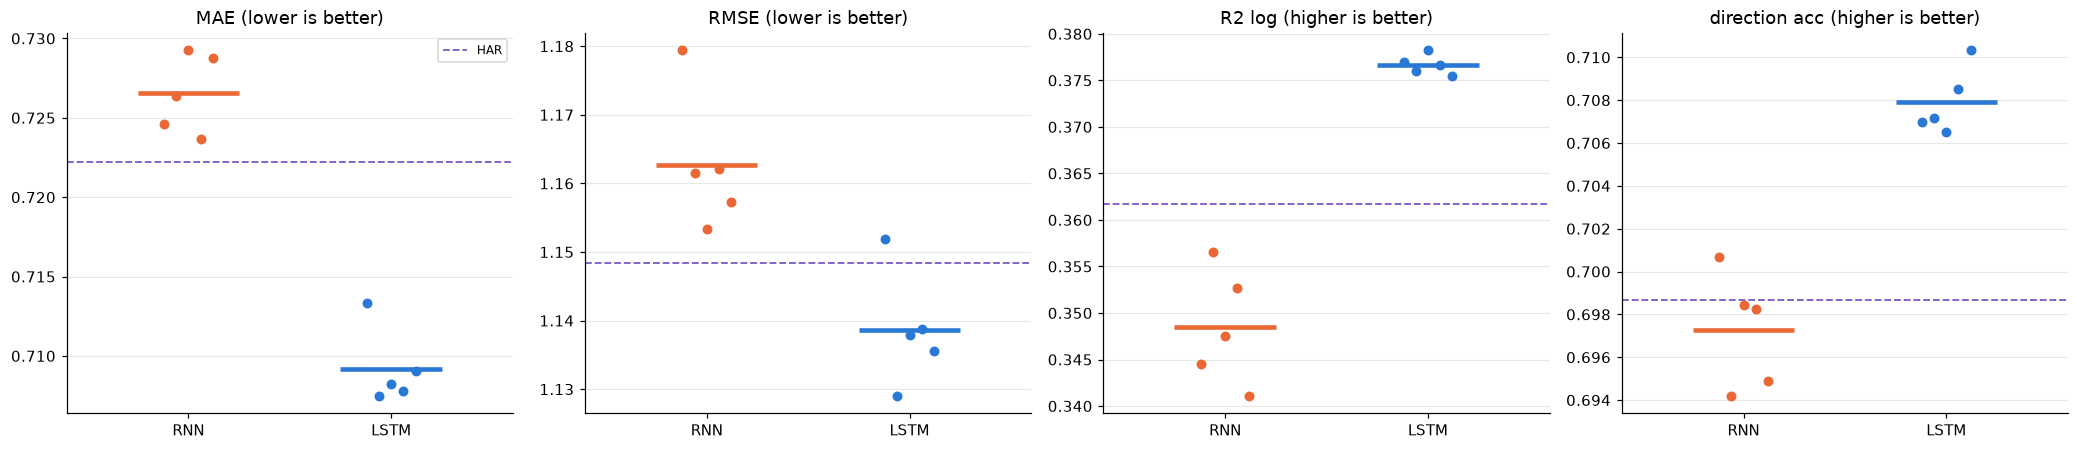

In [13]:
shown = ['MAE', 'RMSE', 'R2 log', 'direction acc']
fig, axes = plt.subplots(1, len(shown), figsize=(19, 4.2))
jitter = np.linspace(-0.12, 0.12, len(SEEDS))
for ax, key in zip(axes, shown):
    for j, cell in enumerate(CELLS):
        values = per_seed.loc[per_seed.model == cell, key].to_numpy()
        ax.scatter(j + jitter, values, color=COLORS[cell], s=30, zorder=3)
        ax.hlines(values.mean(), j - 0.25, j + 0.25, color=COLORS[cell], lw=3)
    ax.axhline(seed42.loc['HAR', key], color=COLORS['HAR'], ls='--', lw=1.2, label='HAR')
    ax.set_xticks(range(len(CELLS)), CELLS)
    ax.set(title=f'{key} ({"lower" if key in LOWER else "higher"} is better)', xlim=(-0.6, 1.6))
    ax.grid(axis='x', visible=False)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / 'lstm_stock_metrics.png')
plt.show()

## 6. Đường học

Train và validation loss (MSE trên mục tiêu chuẩn hóa) theo epoch; đường đậm = seed 42, đường mảnh = các seed khác. A6 cho thấy RNN overfit sớm (val loss thấp nhất ở epoch 4 rồi tăng dần).

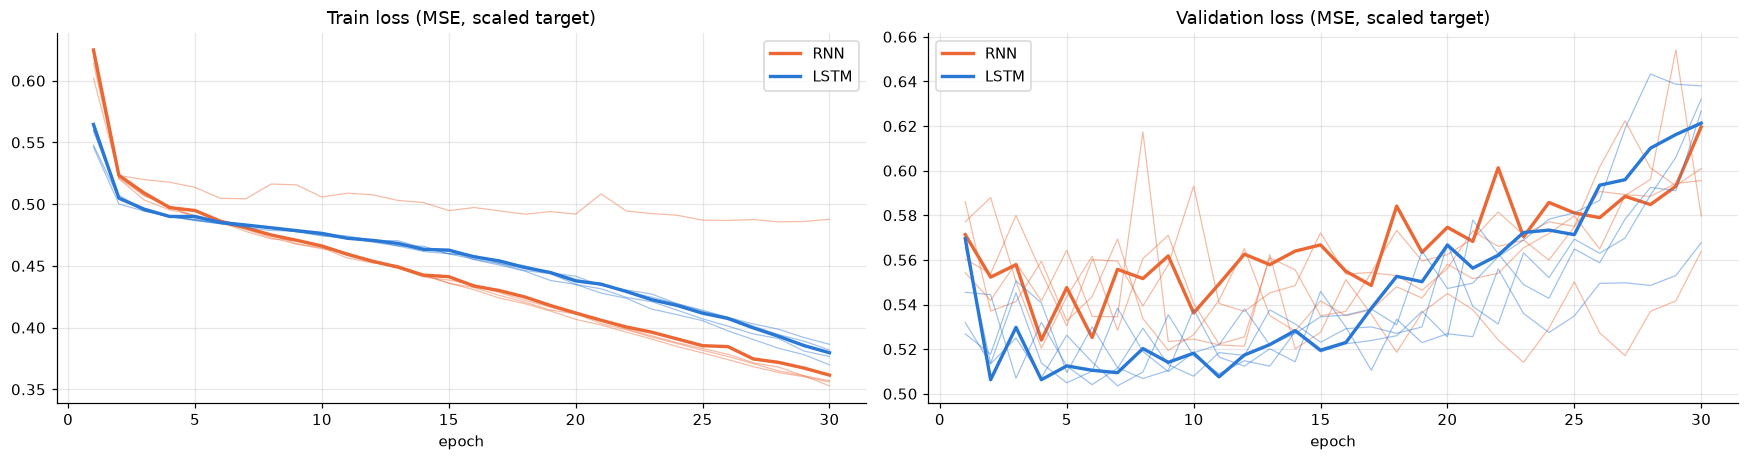

,best epoch (mean),best val loss (mean),final train loss (mean),final val loss (mean)
RNN,9.0,0.5217,0.3830,0.5919
LSTM,6.0,0.5051,0.3789,0.6171


In [14]:
epochs = np.arange(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.3))
for cell in CELLS:
    for seed, r in runs[cell].items():
        style = dict(color=COLORS[cell], lw=2.2 if seed == SEED else 0.8, alpha=1 if seed == SEED else 0.45,
                     label=cell if seed == SEED else None)
        axes[0].plot(epochs, r['history']['loss'], **style)
        axes[1].plot(epochs, r['history']['val_loss'], **style)
axes[0].set(title='Train loss (MSE, scaled target)', xlabel='epoch')
axes[1].set(title='Validation loss (MSE, scaled target)', xlabel='epoch')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'lstm_stock_curves.png')
plt.show()

pd.DataFrame({cell: {'best epoch (mean)': np.mean([r['best_epoch'] for r in runs[cell].values()]),
                     'best val loss (mean)': np.mean([r['best_val_loss'] for r in runs[cell].values()]),
                     'final train loss (mean)': np.mean([r['history']['loss'][-1] for r in runs[cell].values()]),
                     'final val loss (mean)': np.mean([r['history']['val_loss'][-1] for r in runs[cell].values()])}
              for cell in CELLS}).T.round(4)

## 7. Mô hình nhìn xa bao nhiêu ngày?

### 7.1 Độ nhạy theo thời gian

Với 512 cửa sổ test (như A6), tính $\left|\partial \hat y / \partial x_t\right|$ (trung bình trị tuyệt đối, cộng qua 9 đầu vào) bằng autograd, cho từng ngày $t$ của cửa sổ. Ngày 60 là ngày gần nhất. Đường RNN rơi nhanh về bên trái là dấu hiệu **vanishing gradient**: những ngày xa gần như không ảnh hưởng tới dự báo. Bảng: tỉ lệ độ nhạy nằm ở 20 ngày gần nhất, và tỉ số độ nhạy ngày 1 / ngày 60 (trung bình qua 5 seed).

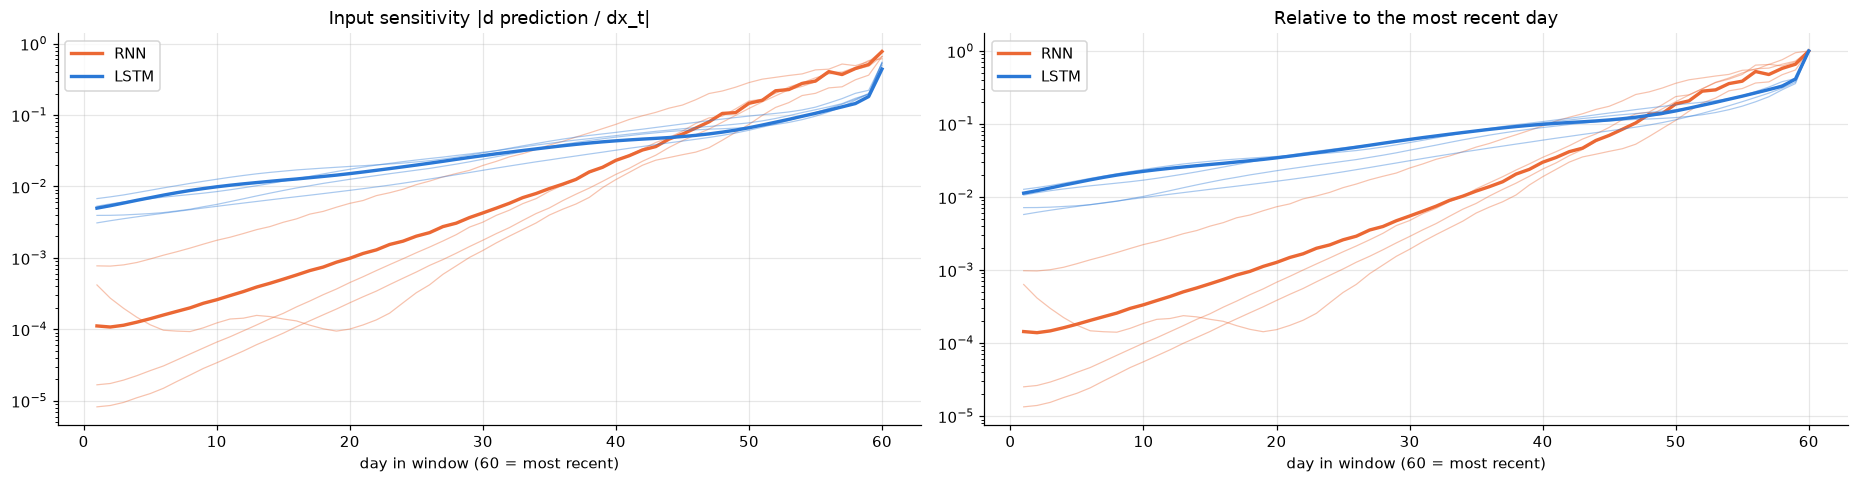

,share in last 5 days,share in last 20 days,share in days 1-40,day 1 / day 60 (median),day 30 / day 60 (median)
RNN,53.507%,96.258%,3.742%,1.44e-04,4.77e-03
LSTM,39.033%,75.036%,24.964%,1.06e-02,5.57e-02


In [15]:
x_sens = X_test[:512]
time_steps = np.arange(1, WINDOW + 1)


def input_sensitivity(model: SeqNet, x: np.ndarray) -> np.ndarray:
    x = torch.from_numpy(x).requires_grad_(True)
    model(x).sum().backward()
    return np.abs(x.grad.numpy()).mean(0).sum(1)              # (T,)


sensitivity = {cell: {seed: input_sensitivity(r['model'], x_sens) for seed, r in runs[cell].items()} for cell in CELLS}

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
for cell in CELLS:
    for seed, s in sensitivity[cell].items():
        style = dict(color=COLORS[cell], lw=2.2 if seed == SEED else 0.8, alpha=1 if seed == SEED else 0.4, label=cell if seed == SEED else None)
        axes[0].plot(time_steps, s, **style)
        axes[1].plot(time_steps, s / s[-1], **style)
axes[0].set(title='Input sensitivity |d prediction / dx_t|', xlabel='day in window (60 = most recent)', yscale='log')
axes[1].set(title='Relative to the most recent day', xlabel='day in window (60 = most recent)', yscale='log')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'lstm_stock_sensitivity.png')
plt.show()

reach = pd.DataFrame({cell: {'share in last 5 days':    np.mean([s[-5:].sum() / s.sum() for s in sensitivity[cell].values()]),
                             'share in last 20 days':   np.mean([s[-20:].sum() / s.sum() for s in sensitivity[cell].values()]),
                             'share in days 1-40':      np.mean([s[:-20].sum() / s.sum() for s in sensitivity[cell].values()]),
                             'day 1 / day 60 (median)': np.median([s[0] / s[-1] for s in sensitivity[cell].values()]),
                             'day 30 / day 60 (median)': np.median([s[29] / s[-1] for s in sensitivity[cell].values()])}
                      for cell in CELLS}).T
reach.style.format('{:.3%}', subset=['share in last 5 days', 'share in last 20 days', 'share in days 1-40']).format('{:.2e}', subset=['day 1 / day 60 (median)', 'day 30 / day 60 (median)'])

### 7.2 Cắt cửa sổ: chỉ giữ k ngày gần nhất

Như mục 11.10 của A6: mô hình đã huấn luyện (seed 42) được chạy trên cửa sổ test mà các ngày cũ hơn k được đặt về 0 (= trung bình train của mỗi đặc trưng; cờ cổ phiếu giữ nguyên). Nếu MAE không đổi khi k vượt một ngưỡng, những ngày trước ngưỡng đó không được dùng. Mô hình nào còn **thay đổi** khi thêm ngày xa là mô hình đang dùng thông tin xa.

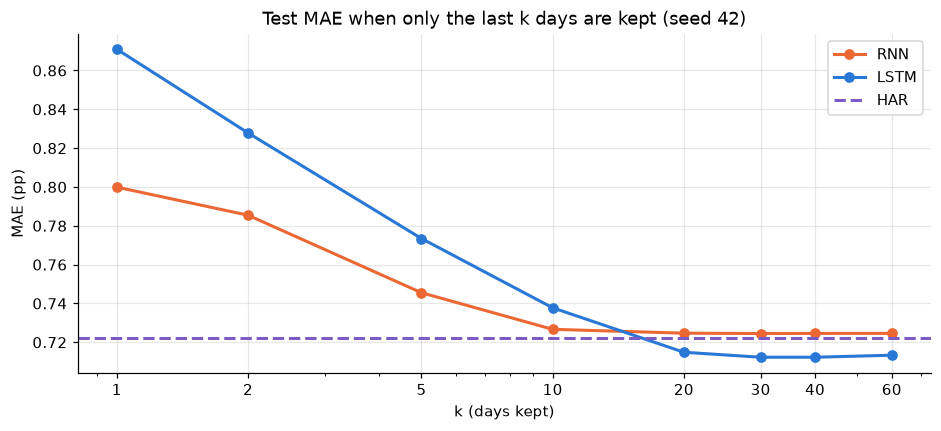

,1,2,5,10,20,30,40,60,change 20 → 60 days
RNN,0.7999,0.7855,0.7455,0.7267,0.7247,0.7245,0.7246,0.7246,-0.0001
LSTM,0.8709,0.8278,0.7734,0.7378,0.7149,0.7123,0.7123,0.7133,-0.0015


In [16]:
K_VALUES = [1, 2, 5, 10, 20, 30, 40, 60]
mae_by_k = {cell: {} for cell in CELLS}
with torch.no_grad():
    for cell in CELLS:
        model = runs[cell][SEED]['model']
        for k in K_VALUES:
            x = X_test.copy()
            x[:, :WINDOW - k, :len(FEATURES)] = 0
            mae_by_k[cell][k] = test_metrics(model(torch.from_numpy(x)).numpy()[:, 0])['MAE']

fig, ax = plt.subplots(figsize=(10, 4))
for cell in CELLS:
    ax.plot(K_VALUES, list(mae_by_k[cell].values()), color=COLORS[cell], marker='o', label=cell)
ax.axhline(seed42.loc['HAR', 'MAE'], color=COLORS['HAR'], ls='--', label='HAR')
ax.set(title='Test MAE when only the last k days are kept (seed 42)', xlabel='k (days kept)', ylabel='MAE (pp)', xscale='log')
ax.set_xticks(K_VALUES, K_VALUES)
ax.legend()
plt.savefig(FIG_DIR / 'lstm_stock_window_cut.png')
plt.show()

cut = pd.DataFrame(mae_by_k).T
cut['change 20 → 60 days'] = cut[60] - cut[20]
cut.round(4)

## 8. Sai số theo cổ phiếu và theo mức biến động

MAE trung bình qua 5 seed. Trái: theo cổ phiếu. Phải: theo mức biến động thật của ngày được dự đoán. Ngày càng biến động mạnh thì mọi mô hình càng dự báo thấp hơn thực tế (không đoán trước được cú sốc).

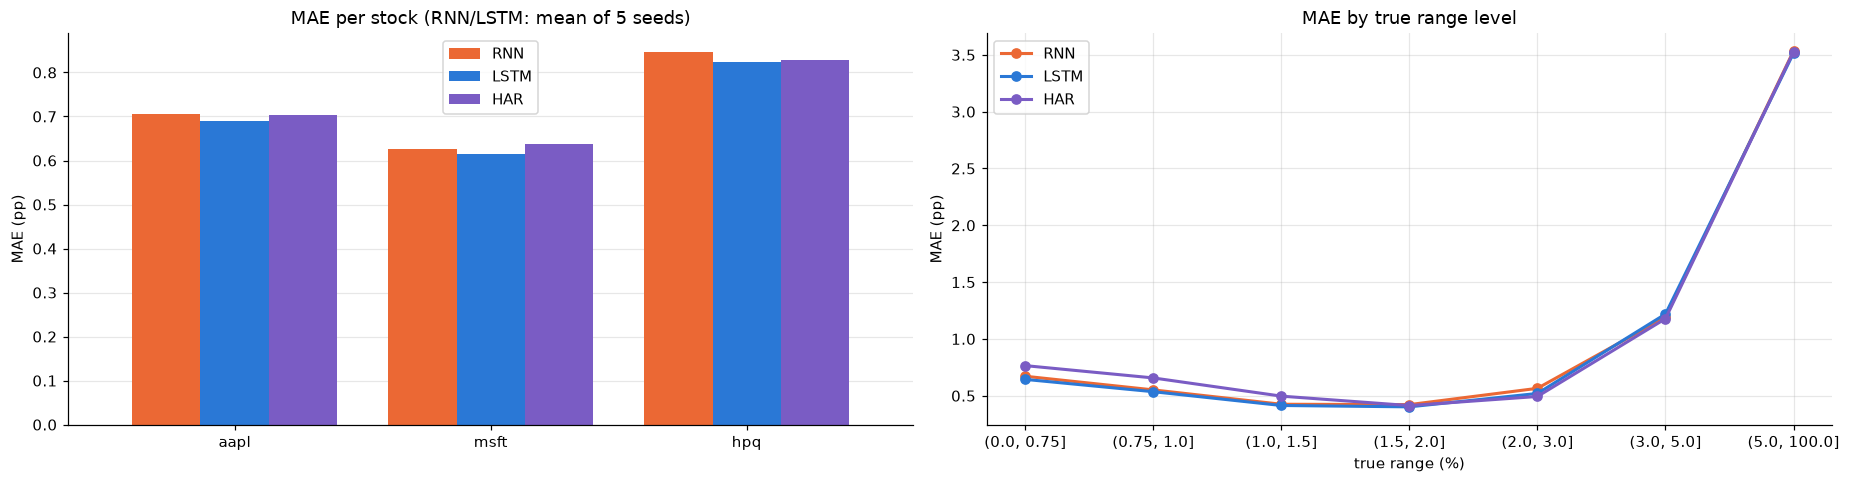

,RNN,LSTM,HAR
aapl,0.7061,0.6902,0.7030
msft,0.6266,0.6142,0.6365
hpq,0.8469,0.8232,0.8272


,RNN,LSTM,HAR,days
"(0.0, 0.75]",0.6716,0.6439,0.7650,37
"(0.75, 1.0]",0.5514,0.5355,0.6568,195
"(1.0, 1.5]",0.4251,0.4142,0.4965,970
"(1.5, 2.0]",0.4219,0.4022,0.4134,1059
"(2.0, 3.0]",0.5652,0.5201,0.4935,1304
"(3.0, 5.0]",1.1905,1.2191,1.1782,713
"(5.0, 100.0]",3.5345,3.5156,3.5284,189


In [17]:
y_true_pct = 100 * np.exp(true_log)
level = pd.cut(y_true_pct, [0, 0.75, 1, 1.5, 2, 3, 5, 100])
abs_err = {cell: np.mean([np.abs(100 * np.exp(to_log(r['test_z'])) - y_true_pct) for r in runs[cell].values()], axis=0) for cell in CELLS}
abs_err['HAR'] = np.abs(100 * np.exp(test_meta.har.to_numpy()) - y_true_pct)
abs_err = pd.DataFrame(abs_err)

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
by_ticker = abs_err.groupby(test_meta.ticker.to_numpy()).mean().loc[TICKERS]
by_ticker.plot.bar(ax=axes[0], color=[COLORS[c] for c in abs_err.columns], rot=0, width=0.8)
axes[0].set(title='MAE per stock (RNN/LSTM: mean of 5 seeds)', ylabel='MAE (pp)')
axes[0].grid(axis='x', visible=False)
by_level = abs_err.groupby(level, observed=True).mean()
for name in abs_err.columns:
    axes[1].plot(by_level.index.astype(str), by_level[name], color=COLORS[name], marker='o', label=name)
axes[1].set(title='MAE by true range level', xlabel='true range (%)', ylabel='MAE (pp)')
axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'lstm_stock_errors.png')
plt.show()

display(by_ticker.round(4))
by_level.assign(days=pd.Series(level).value_counts().sort_index().to_numpy()).round(4)

## 9. Thí nghiệm độ dài cửa sổ: 20 / 60 / 120 ngày

Tự tương quan của biên độ vẫn còn ≈ 0.32 ở độ trễ 100 ngày (A6, mục 3.3), nên về lý thuyết cửa sổ dài hơn có thông tin. Câu hỏi: **mô hình nào khai thác được cửa sổ dài?**

Để so sánh các độ dài trên **cùng một tập mẫu**, cửa sổ 120 ngày được tạo trước (bỏ mẫu chạm ngày lỗi trong 121 ngày), rồi cửa sổ 20 và 60 là 20 / 60 ngày cuối của chính các mẫu đó. Vì bộ lọc ngày lỗi chặt hơn, tập mẫu ở đây hơi nhỏ hơn mục 4–8, nên con số không so trực tiếp với bảng 5.x. Mỗi cấu hình chạy 3 seed (42, 0, 1), cùng siêu tham số.

In [18]:
LONG = max(SWEEP_WINDOWS)
Xl, yl, metal = [], [], []
for ticker, f in frames.items():
    log_range = f.log_range
    windows = np.lib.stride_tricks.sliding_window_view(f[INPUTS].to_numpy('float32')[:-1], LONG, axis=0).transpose(0, 2, 1)
    touches_bad = np.lib.stride_tricks.sliding_window_view(f.bad.to_numpy(), LONG + 1).any(axis=1)
    keep = ~touches_bad & (f.index[LONG:] >= FIRST_TARGET)
    Xl.append(windows[keep])
    yl.append(((log_range - stats.loc['mean', 'range']) / stats.loc['std', 'range']).to_numpy('float32')[LONG:, None][keep])
    metal.append(pd.DataFrame({'ticker': ticker, 'target_day': f.index[LONG:], 'true': log_range.to_numpy()[LONG:],
                               'naive': log_range.to_numpy()[LONG - 1:-1], 'mean5': log_range.rolling(5).mean().to_numpy()[LONG - 1:-1],
                               'mean22': log_range.rolling(22).mean().to_numpy()[LONG - 1:-1]})[keep])
Xl, yl, metal = np.concatenate(Xl), np.concatenate(yl), pd.concat(metal, ignore_index=True)
metal['split'] = np.select([metal.target_day < VAL_START, metal.target_day < TEST_START], ['train', 'val'], 'test')
metal['har'] = har.predict(metal[['naive', 'mean5', 'mean22']])
masks = {s: (metal.split == s).to_numpy() for s in ['train', 'val', 'test']}
test_metal = metal[masks['test']].reset_index(drop=True)
print(f'{LONG}-day windows: {len(Xl):,} (main experiment: {len(X):,}) | train {masks["train"].sum():,} | val {masks["val"].sum():,} | test {masks["test"].sum():,}')

sweep_metrics = lambda z: regression_metrics(test_metal.true.to_numpy(), to_log(z), test_metal.naive.to_numpy())
sweep = []
for W in SWEEP_WINDOWS:
    data = {'X_train': np.ascontiguousarray(Xl[masks['train']][:, -W:]), 'y_train': yl[masks['train']],
            'X_val':   np.ascontiguousarray(Xl[masks['val']][:, -W:]),   'y_val':   yl[masks['val']],
            'X_test':  np.ascontiguousarray(Xl[masks['test']][:, -W:])}
    for seed in SWEEP_SEEDS:
        for cell in CELLS:
            r = train(cell, seed, data)
            m = sweep_metrics(r['test_z'])
            sweep.append({'window': W, 'model': cell, 'seed': seed, 'best_epoch': r['best_epoch'], 'val_loss': r['best_val_loss'],
                          's_per_epoch': np.mean(r['history']['epoch_time'])} | m)
            print(f'W={W:>3} {cell:<4} seed {seed}: best epoch {r["best_epoch"]:>2} | val loss {r["best_val_loss"]:.4f} | test MAE {m["MAE"]:.4f} | '
                  f'R2 log {m["R2 log"]:.4f} | {np.mean(r["history"]["epoch_time"]):.1f} s/epoch')
sweep = pd.DataFrame(sweep)

120-day windows: 23,103 (main experiment: 23,223) | train 16,374 | val 2,262 | test 4,467


W= 20 RNN  seed 42: best epoch  4 | val loss 0.5217 | test MAE 0.7230 | R2 log 0.3420 | 0.8 s/epoch


W= 20 LSTM seed 42: best epoch 10 | val loss 0.5023 | test MAE 0.7133 | R2 log 0.3712 | 1.3 s/epoch


W= 20 RNN  seed 0: best epoch  2 | val loss 0.5359 | test MAE 0.7176 | R2 log 0.3652 | 0.7 s/epoch


W= 20 LSTM seed 0: best epoch  7 | val loss 0.5075 | test MAE 0.7056 | R2 log 0.3857 | 1.0 s/epoch


...

W=120 LSTM seed 42: best epoch  7 | val loss 0.5052 | test MAE 0.7120 | R2 log 0.3646 | 4.5 s/epoch


W=120 RNN  seed 0: best epoch 12 | val loss 0.5386 | test MAE 0.7367 | R2 log 0.3284 | 3.5 s/epoch


W=120 LSTM seed 0: best epoch 12 | val loss 0.5080 | test MAE 0.7182 | R2 log 0.3660 | 4.5 s/epoch


W=120 RNN  seed 1: best epoch  5 | val loss 0.5327 | test MAE 0.7266 | R2 log 0.3518 | 3.1 s/epoch


W=120 LSTM seed 1: best epoch  7 | val loss 0.5070 | test MAE 0.7107 | R2 log 0.3842 | 4.7 s/epoch


MAE            RMSE          R2 log         direction acc          \
model     LSTM     RNN    LSTM     RNN    LSTM     RNN          LSTM     RNN   
window                                                                         
20      0.7096  0.7227  1.1331  1.1620  0.3801  0.3529        0.7094  0.7008   
60      0.7122  0.7284  1.1355  1.1654  0.3745  0.3416        0.7066  0.6965   
120     0.7137  0.7284  1.1371  1.1655  0.3716  0.3415        0.7056  0.6964   

       val_loss         best_epoch         s_per_epoch          
model      LSTM     RNN       LSTM     RNN        LSTM     RNN  
window                                                          
20       0.5054  0.5302     7.6667  3.6667      1.1517  0.7139  
60       0.5070  0.5302     8.6667  7.0000      2.2765  1.6482  
120      0.5067  0.5302     8.6667  7.0000      4.5679  3.2387

HAR on the same test windows: MAE 0.7222 | RMSE 1.1483 | R2 log 0.3618


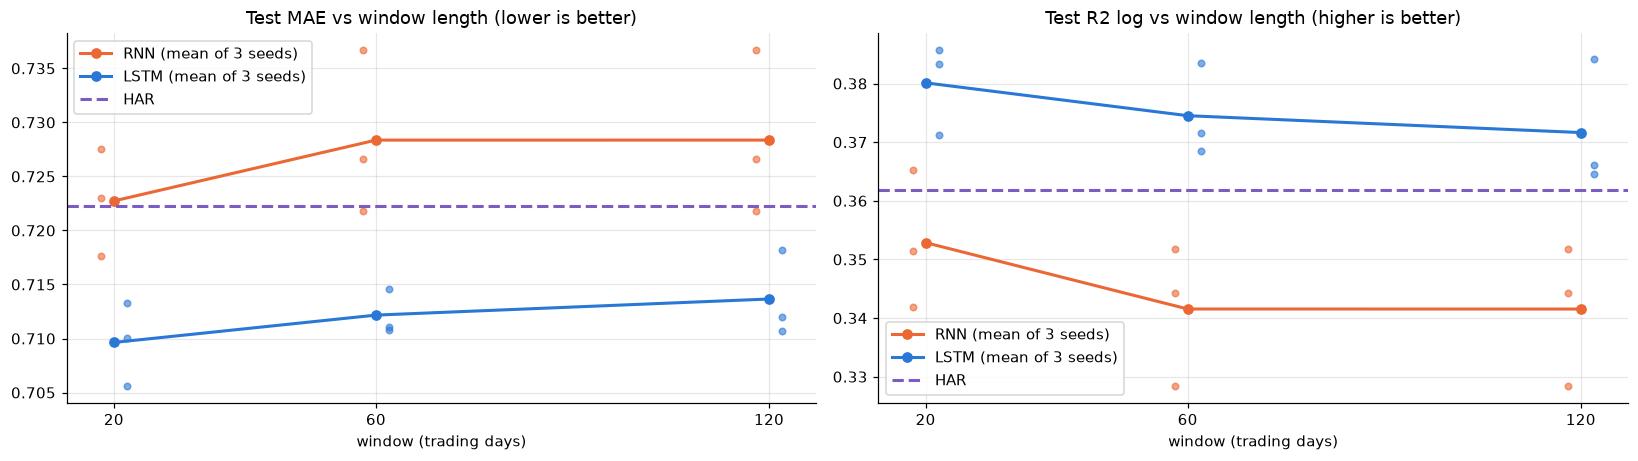

In [19]:
har_sweep = regression_metrics(test_metal.true.to_numpy(), test_metal.har.to_numpy(), test_metal.naive.to_numpy())
sweep_table = sweep.groupby(['window', 'model'])[['MAE', 'RMSE', 'R2 log', 'direction acc', 'val_loss', 'best_epoch', 's_per_epoch']].mean().unstack('model')
display(sweep_table.round(4))
print(f'HAR on the same test windows: MAE {har_sweep["MAE"]:.4f} | RMSE {har_sweep["RMSE"]:.4f} | R2 log {har_sweep["R2 log"]:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
for ax, key in zip(axes, ['MAE', 'R2 log']):
    for cell in CELLS:
        part = sweep[sweep.model == cell]
        ax.scatter(part.window + (-2 if cell == 'RNN' else 2), part[key], color=COLORS[cell], s=18, alpha=0.6)
        ax.plot(SWEEP_WINDOWS, part.groupby('window')[key].mean(), color=COLORS[cell], marker='o', label=f'{cell} (mean of {len(SWEEP_SEEDS)} seeds)')
    ax.axhline(har_sweep[key], color=COLORS['HAR'], ls='--', label='HAR')
    ax.set(title=f'Test {key} vs window length ({"lower" if key in LOWER else "higher"} is better)', xlabel='window (trading days)')
    ax.set_xticks(SWEEP_WINDOWS)
    ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'lstm_stock_window_sweep.png')
plt.show()

## 10. Chi phí, lưu kết quả và kết luận

In [20]:
cost = pd.DataFrame({cell: {'trainable parameters': runs[cell][SEED]['params'],
                            's / epoch (mean)': np.mean([np.mean(r['history']['epoch_time']) for r in runs[cell].values()]),
                            'training time s (mean)': np.mean([r['train_time'] for r in runs[cell].values()]),
                            f'inference ms on {len(X_test):,} windows (mean)': 1000 * np.mean([r['infer_time'] for r in runs[cell].values()])}
                     for cell in CELLS}).T
cost.loc['LSTM / RNN'] = cost.loc['LSTM'] / cost.loc['RNN']
cost.round(2)

,trainable parameters,s / epoch (mean),training time s (mean),"inference ms on 4,467 windows (mean)"
RNN,7873.00,1.96,58.76,83.03
LSTM,31393.00,2.87,86.25,153.50
LSTM / RNN,3.99,1.47,1.47,1.85


In [21]:
out = {
    'task': 'next-day trading range ln(High/Low) of aapl, msft, hpq from a 60-day window',
    'config': {'window': WINDOW, 'hidden': [H1, H2], 'batch': BATCH_SIZE, 'epochs': EPOCHS, 'lr': LR, 'clip': CLIP, 'seeds': SEEDS,
               'n_train': len(X_train), 'n_val': len(X_val), 'n_test': len(X_test)},
    'a6_rnn_reference': A6_RNN,
    'per_seed': per_seed.to_dict(orient='records'),
    'mean': {cell: per_seed[per_seed.model == cell][keys + ['MAE vs HAR %']].mean().to_dict() for cell in CELLS},
    'std': {cell: per_seed[per_seed.model == cell][keys + ['MAE vs HAR %']].std().to_dict() for cell in CELLS},
    'lstm_wins': wins.to_dict(),
    'references': {name: seed42.loc[name].to_dict() for name in ['naive', 'mean 5 days', 'mean 20 days', 'HAR']},
    'curves': {cell: {str(seed): {k: [float(v) for v in r['history'][k]] for k in ['loss', 'val_loss']}
                      for seed, r in runs[cell].items()} for cell in CELLS},
    'sensitivity_seed42_relative_to_day60': {cell: (sensitivity[cell][SEED] / sensitivity[cell][SEED][-1]).tolist() for cell in CELLS},
    'reach': reach.to_dict(orient='index'),
    'mae_by_k_seed42': {cell: {str(k): v for k, v in d.items()} for cell, d in mae_by_k.items()},
    'mae_by_ticker': by_ticker.to_dict(orient='index'),
    'window_sweep': {'per_run': sweep.to_dict(orient='records'), 'har': har_sweep,
                     'mean': {f'{W} | {cell}': sweep[(sweep.window == W) & (sweep.model == cell)][['MAE', 'RMSE', 'R2 log', 'direction acc']].mean().to_dict()
                              for W in SWEEP_WINDOWS for cell in CELLS}},
    'cost': cost.to_dict(orient='index'),
}
(RESULT_DIR / 'lstm_stock.json').write_text(json.dumps(out, indent=1, default=float), encoding='utf-8')
print('saved', RESULT_DIR / 'lstm_stock.json')

print()
for cell in CELLS:
    m = out['mean'][cell]
    print(f'{cell:<5} (mean of {len(SEEDS)} seeds) MAE {m["MAE"]:.4f} ({m["MAE vs HAR %"]:+.1f} % vs HAR) | RMSE {m["RMSE"]:.4f} | '
          f'R2 log {m["R2 log"]:.4f} | direction {m["direction acc"]:.4f}')
for name in ['naive', 'mean 5 days', 'HAR']:
    m = seed42.loc[name]
    print(f'{name:<12} MAE {m["MAE"]:.4f} | RMSE {m["RMSE"]:.4f} | R2 log {m["R2 log"]:.4f}')
print('\nLSTM better than RNN (same seed):', {k: f'{v}/{len(SEEDS)}' for k, v in wins.items()})
print('share of the sensitivity in days 1-40:', {cell: f'{reach.loc[cell, "share in days 1-40"]:.2%}' for cell in CELLS})
print('window sweep, mean test MAE:', {f'W={W}': {cell: round(out['window_sweep']['mean'][f'{W} | {cell}']['MAE'], 4) for cell in CELLS} for W in SWEEP_WINDOWS})

saved results/lstm_stock.json

RNN   (mean of 5 seeds) MAE 0.7265 (+0.6 % vs HAR) | RMSE 1.1627 | R2 log 0.3485 | direction 0.6973
LSTM  (mean of 5 seeds) MAE 0.7092 (-1.8 % vs HAR) | RMSE 1.1386 | R2 log 0.3767 | direction 0.7079
naive        MAE 0.8943 | RMSE 1.3157 | R2 log 0.0507
mean 5 days  MAE 0.7492 | RMSE 1.1577 | R2 log 0.3070
HAR          MAE 0.7222 | RMSE 1.1483 | R2 log 0.3618

LSTM better than RNN (same seed): {'MAE': '5/5', 'RMSE': '5/5', 'MAPE %': '4/5', 'R2 log': '5/5', 'direction acc': '5/5'}
share of the sensitivity in days 1-40: {'RNN': '3.74%', 'LSTM': '24.96%'}
window sweep, mean test MAE: {'W=20': {'RNN': 0.7227, 'LSTM': 0.7096}, 'W=60': {'RNN': 0.7284, 'LSTM': 0.7122}, 'W=120': {'RNN': 0.7284, 'LSTM': 0.7137}}


**Nhận xét về lần chạy này**

- **Tái lập A6.** RNN seed 42 cho đúng số của A6: MAE 0.7246 điểm %, R² log 0.3445, best epoch 4.
- **LSTM tốt hơn RNN ở mọi chỉ số chính, cả 5/5 seed:** MAE 0.7092 ± 0.0024 so với 0.7265 ± 0.0025 (thấp hơn 2.4 %), RMSE 1.139 so với 1.163, R² log 0.377 so với 0.349, direction accuracy 0.708 so với 0.697. Seed tệ nhất của LSTM (MAE 0.7133) vẫn tốt hơn seed tốt nhất của RNN (0.7237).
- **LSTM vượt HAR, RNN thì không.** HAR có MAE 0.7222. LSTM tốt hơn HAR 1.8 % (cả 5 seed), còn RNN kém HAR 0.6 %. LSTM tốt hơn HAR ở cả 3 cổ phiếu. LSTM cũng ổn định hơn: độ lệch chuẩn của R² log là 0.001, của RNN là 0.006.
- **Vanishing gradient thấy rõ trên số liệu.** Với RNN, độ nhạy của dự báo theo ngày 1 chỉ bằng 1.4e-4 lần ngày 60. 96 % độ nhạy nằm ở 20 ngày cuối, chỉ 3.7 % ở 40 ngày đầu. Với LSTM, tỉ số này là 1.1e-2 (lớn hơn ≈ 75 lần), và 25 % độ nhạy nằm ở 40 ngày đầu. Ở thí nghiệm độ dài cửa sổ, RNN với cửa sổ 120 ngày cho kết quả **trùng khớp đến 4 chữ số** với cửa sổ 60 ngày: 60 ngày thêm vào hoàn toàn không ảnh hưởng tới dự báo.
- **Cần nói rõ khi trình bày:** lợi thế của LSTM ở đây **không** đến từ việc dùng cửa sổ dài hơn. Cửa sổ 20 ngày cho MAE tốt nhất với cả hai mô hình (LSTM 0.7096, RNN 0.7227), và LSTM tốt hơn RNN ở mọi độ dài cửa sổ. Khi cắt cửa sổ, LSTM chỉ cải thiện 0.0015 khi đi từ 20 lên 60 ngày. Thông tin chính nằm trong khoảng 20 ngày gần nhất (giống thành phần 22 ngày của HAR). LSTM thắng vì các cổng giúp nó tính trung bình biến động trên ~20 ngày tốt hơn, và vì nó tối ưu ổn định hơn.
- **Chi phí:** số tham số gấp ≈ 4 lần (31,393 so với 7,873), mỗi epoch chậm hơn ≈ 1.5 lần, suy luận chậm hơn ≈ 1.9 lần.